### Setup & Library Import

Using librosa for audio processing and tensorflow for modeling.

L2 regularization is imported to prevent overfitting on the small dataset.

Initialize GPU for faster training.

In [1]:
# --- IMPORTS ---
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import librosa
import librosa.display
import IPython.display as ipd
import tensorflow as tf

# Scikit-Learn and Keras utilities
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.regularizers import l2


# --- CONFIGURATION PARAMETERS ---
AUDIO_DIR = "dataset/audio/"
META_FILE = "dataset/esc50.csv"
TARGET_ANIMALS = ['dog', 'cat', 'rooster', 'cow', 'pig', 'sheep', 'frog', 'crow', 'hen']

# Audio Constants (Synced perfectly with Meyda.js in the browser)
SAMPLE_RATE = 22050 # How many audio snapshots per second (22,050 Hz is standard for Librosa)
DURATION = 2.9      # Only look at the first 2.9 seconds of every clip
N_MFCC = 40         # How many features to extract per time step (40 = High Definition)
N_FFT = 512         # The window size for analyzing frequencies (512 matches the JS frontend)
HOP_LENGTH = 512    # How many samples to skip before the next analysis (512 = No Overlap)
MAX_FRAMES = 130    # The fixed width of the input image (Time steps)

# --- GPU INITIALIZATION ---
print(f"TensorFlow Version: {tf.__version__}") 

# Locate physical GPU devices
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    try:
        # Prevent TensorFlow from grabbing all VRAM at once (prevents "Out of Memory" errors)
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU Detected: {gpus}")
        print("Memory Growth Enabled")
    except RuntimeError as e:
        # In case the GPU is already initialized
        print(f"GPU Status: {e}")
else:
    print("No GPU found. Training will use CPU (Slow).")

print("Environment Ready.")

TensorFlow Version: 2.10.0


GPU Detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Memory Growth Enabled
Environment Ready.


### Data Exploration

This section visualizes the raw waveform vs. the MFCCs to justify why use MFCCs for the AI.

Check class distribution to ensure the dataset is balanced.

Total Samples: 360
Class Distribution:
category
dog        40
crow       40
sheep      40
frog       40
cow        40
hen        40
pig        40
rooster    40
cat        40
Name: count, dtype: int64


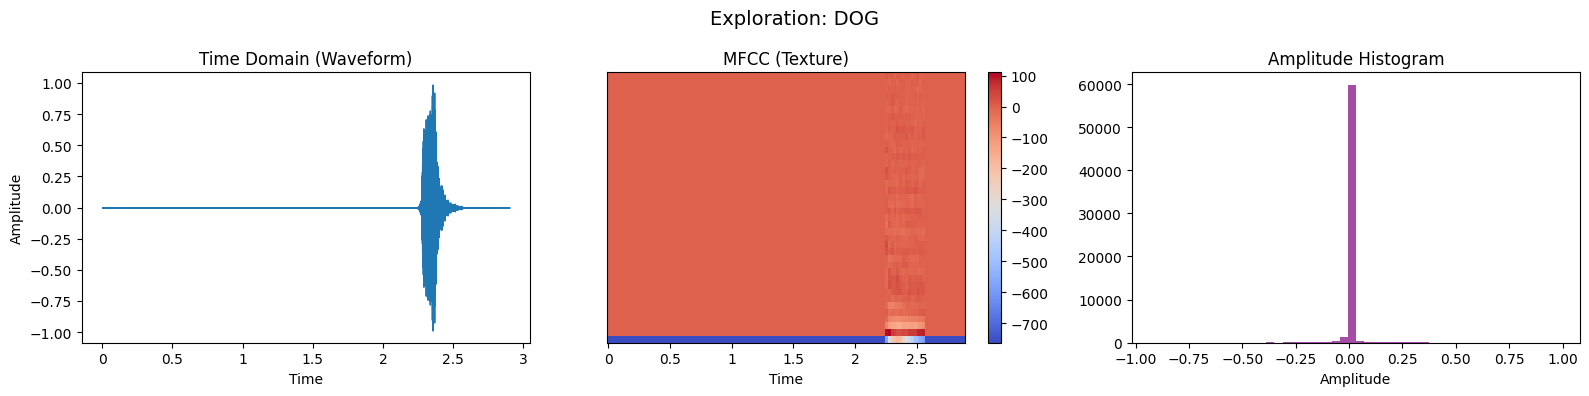

Playing dog...


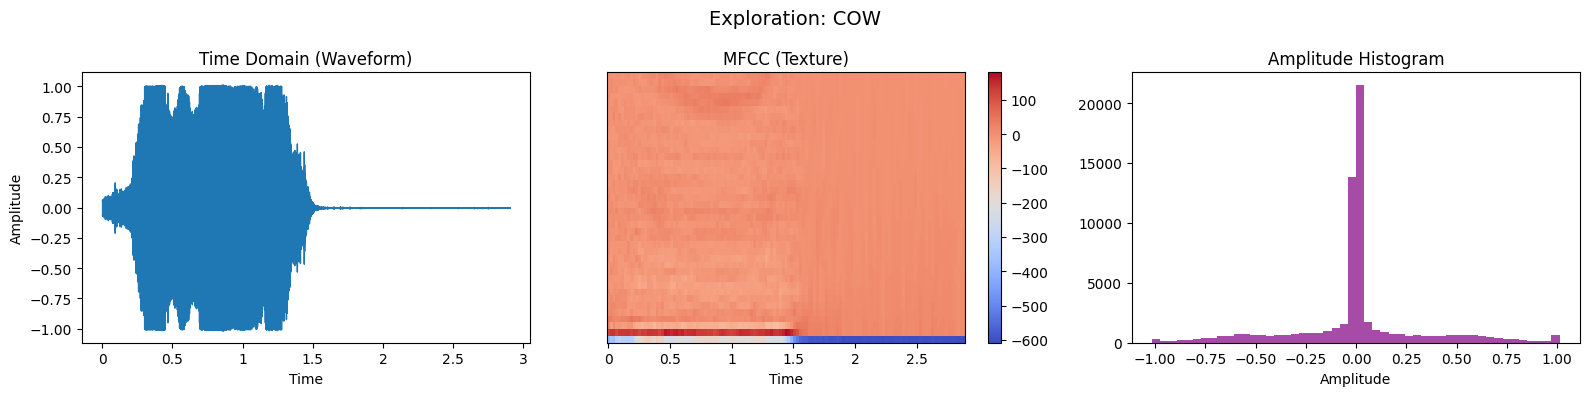

Playing cow...


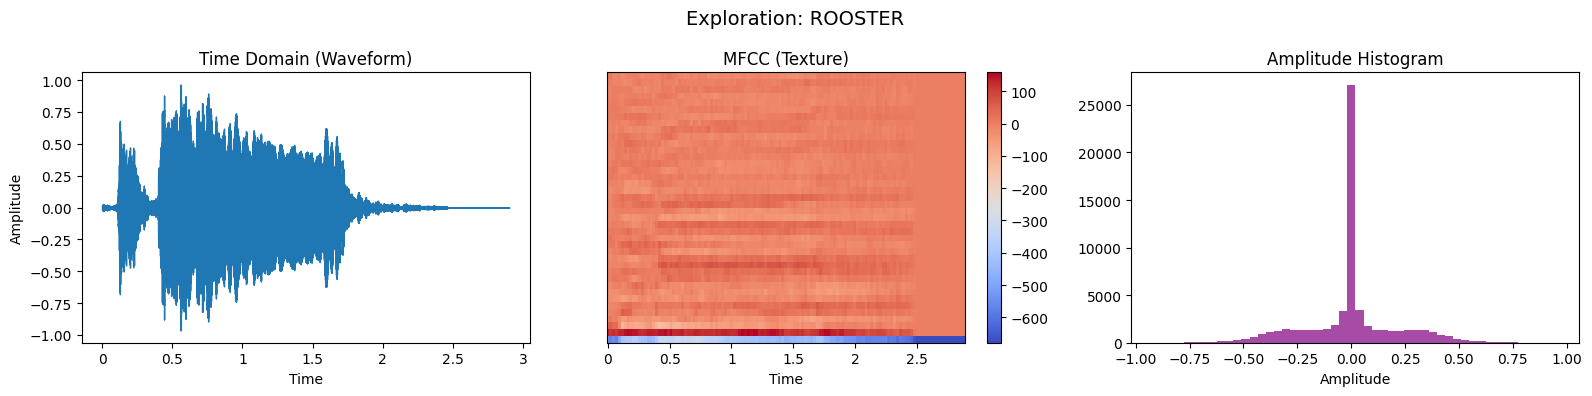

Playing rooster...


In [2]:
# Load the CSV file into a Pandas DataFrame
metadata = pd.read_csv(META_FILE)
# Keep only the rows where the category matches our target animals (Dog, Cat, etc.)
df = metadata[metadata['category'].isin(TARGET_ANIMALS)]

# Print the total number of files we found
print(f"Total Samples: {len(df)}")
# Print how many files exist for each animal (to check if data is balanced)
print("Class Distribution:")
print(df['category'].value_counts())

# Define a function to visualize the audio data for a specific animal
def explore_data(animal_class):
    """
    Visualizes Waveform, Spectrum, and MFCC to understand feature suitability.
    """
    # Find the first row in the dataset that matches the requested animal
    row = df[df['category'] == animal_class].iloc[0]
    # Construct the full path to the audio file
    file_path = os.path.join(AUDIO_DIR, row['filename'])
    
    # Load the audio file (y = audio data, sr = 22050Hz)
    y, sr = librosa.load(file_path, sr=SAMPLE_RATE, duration=DURATION)
    
    # Create a figure with 3 side-by-side plots
    plt.figure(figsize=(16, 4))
    # Add a main title to the figure
    plt.suptitle(f"Exploration: {animal_class.upper()}", fontsize=14)
    
    # --- PLOT 1: WAVEFORM ---
    # Select the first subplot
    plt.subplot(1, 3, 1)
    # Draw the loudness over time
    librosa.display.waveshow(y, sr=sr)
    # Set titles and labels
    plt.title("Time Domain (Waveform)")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    
    # --- PLOT 2: MFCC ---
    # Select the second subplot
    plt.subplot(1, 3, 2)
    # Calculate MFCC features (Texture)
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH)
    # Draw the MFCC heatmap
    librosa.display.specshow(mfccs, sr=sr, x_axis='time')
    # Set title and add color bar
    plt.title("MFCC (Texture)")
    plt.colorbar()
    
    # --- PLOT 3: ENERGY ---
    # Select the third subplot
    plt.subplot(1, 3, 3)
    # Draw a histogram to show how loud the file is generally
    plt.hist(y, bins=50, color='purple', alpha=0.7)
    # Set titles and labels
    plt.title("Amplitude Histogram")
    plt.xlabel("Amplitude")
    
    # Adjust layout so plots don't overlap
    plt.tight_layout()
    # Show the plots
    plt.show()
    
    # Print message and show an audio player widget
    print(f"Playing {animal_class}...")
    display(ipd.Audio(file_path))

# Loop through 3 example animals and run the visualization function
for animal in ['dog', 'cow', 'rooster']:
    explore_data(animal)

### Pre-processing & Feature Engineering

Applying Z-Score Standardization (Scaling) because Neural Networks converge faster when inputs are centered around 0.

Perform Data Augmentation (Noise, Shift) to address the limited dataset size.

Clips are split into training and validation **before** augmentation, so no single recording ever appears in both sets.


In [3]:
# --- DATA AUGMENTATION ---

# Function to add random static noise to audio (simulates bad microphones)
def add_noise(data):
    # Calculate noise level (0.4% of the loudest part of the audio)
    noise_amp = 0.004 * np.random.uniform() * np.amax(data)
    # Add the noise to the original audio
    data = data + noise_amp * np.random.normal(size=data.shape)
    # Return the noisy audio
    return data

# Function to shift audio left or right (simulates timing differences)
def time_shift(data):
    # Calculate maximum shift amount (30% of total length)
    shift_range = int(len(data) * 0.3)
    # Pick a random amount to shift
    shift_amt = np.random.randint(-shift_range, shift_range)
    # Perform the shift (wrapping around edges)
    return np.roll(data, shift_amt)

# Function to load audio file from disk
def extract_features(file_path):
    try:
        # Load file at 22050Hz, max 2.9 seconds
        audio, sr = librosa.load(file_path, sr=SAMPLE_RATE, duration=2.9)
        return audio, sr
    except:
        # If file is broken, return nothing
        return None, None

# Function to convert raw audio into AI-ready numbers (MFCCs)
def get_mfcc(audio, sr):
    # 1. MFCC: Convert wave to heatmap (Texture)
    # lifter=0 matches the raw output format of the JavaScript library (Meyda)
    mfccs = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH, lifter=0)
    # Transpose matrix to match shape (Time, Features)
    mfccs = mfccs.T 
    
    # 2. DROP 0th Coefficient: This feature represents Volume.
    # remove it so the AI focuses on Sound Texture, not Loudness.
    # keep columns 1 to 39 (Total 39 features).
    mfccs = mfccs[:, 1:] 
    
    # 3. Standardize (Z-Score): Scale numbers to average 0
    # This helps the Neural Network learn faster
    mean = np.mean(mfccs)
    std = np.std(mfccs)
    mfccs = (mfccs - mean) / (std + 1e-6)
    
    # 4. Pad / Trim: Ensure every file is exactly MAX_FRAMES long
    target_cols = N_MFCC - 1 # 39 features
    if mfccs.shape[0] < MAX_FRAMES:
        # If too short, create a block of zeros
        padding = np.zeros((MAX_FRAMES - mfccs.shape[0], target_cols))
        # Add zeros to the end
        mfccs = np.vstack((mfccs, padding))
    elif mfccs.shape[0] > MAX_FRAMES:
        # If too long, cut off the end
        mfccs = mfccs[:MAX_FRAMES]
        
    return mfccs

# --- GENERATE DATASET ---
# Read the list of files
metadata = pd.read_csv(META_FILE)
# Filter list to only include our 9 target animals
subset = metadata[metadata['category'].isin(TARGET_ANIMALS)]

# --- LEAK-FREE SPLIT ---
# Split the CLIPS first, then augment only the training clips.
# Splitting after augmentation would put the noise/shifted copies of a validation
# clip into the training set, and the model would just recognise the same recording.
train_df, val_df = train_test_split(
    subset, test_size=0.2, random_state=7204, stratify=subset['category']
)
print(f"Clips -> train: {len(train_df)} | validation: {len(val_df)}")

# Seed the augmentation so the noisy/shifted versions are reproducible
np.random.seed(7204)

def build_samples(frame, augment):
    """Turn clips into MFCC images. Only the training set is augmented."""
    feats, labs = [], []
    for _, row in frame.iterrows():
        audio_raw, sr = extract_features(os.path.join(AUDIO_DIR, row['filename']))
        if audio_raw is None:
            continue
        cat = row['category']
        # 1. Original audio — always kept
        feats.append(get_mfcc(audio_raw, sr))
        labs.append(cat)
        if augment:
            # 2. Noisy version (simulates a bad microphone)
            feats.append(get_mfcc(add_noise(audio_raw), sr))
            labs.append(cat)
            # 3. Shifted version (simulates timing differences)
            feats.append(get_mfcc(time_shift(audio_raw), sr))
            labs.append(cat)
    return feats, labs

print("Processing Dataset...")
train_features, train_labels = build_samples(train_df, augment=True)
val_features, val_labels = build_samples(val_df, augment=False)

def to_images(feats):
    """Reshape for the CNN: (Samples, 130 Time Steps, 39 Features, 1 Channel)."""
    arr = np.array(feats)
    return arr.reshape(arr.shape[0], MAX_FRAMES, N_MFCC - 1, 1)

X_train = to_images(train_features)
X_val = to_images(val_features)

# Convert text labels ("dog") to numbers, then to One-Hot Vectors.
# The encoder is fitted once on every clip so the class order is stable.
le = LabelEncoder()
le.fit(subset['category'])
y_train = to_categorical(le.transform(train_labels))
y_val = to_categorical(le.transform(val_labels))

print(f"Train Shape: {X_train.shape} | Validation Shape: {X_val.shape}")
print(f"Classes: {le.classes_}")


Clips -> train: 288 | validation: 72
Processing Dataset...


Train Shape: (864, 130, 39, 1) | Validation Shape: (72, 130, 39, 1)
Classes: ['cat' 'cow' 'crow' 'dog' 'frog' 'hen' 'pig' 'rooster' 'sheep']


### Baseline Model Training

Using a Convolutional Neural Network (CNN). CNNs are the industry standard for image classification, and by treating MFCCs as images, leverage their ability to detect spatial patterns (sound textures).

Smart callbacks, such as create a tool that automatically lowers the "speed" of learning.

Training Model...
Epoch 1/200


27/27 - 17s - loss: 4.4584 - accuracy: 0.2870 - val_loss: 4.4073 - val_accuracy: 0.1667 - lr: 0.0010 - 17s/epoch - 611ms/step


Epoch 2/200


27/27 - 1s - loss: 3.5719 - accuracy: 0.5162 - val_loss: 4.1738 - val_accuracy: 0.1111 - lr: 0.0010 - 787ms/epoch - 29ms/step


Epoch 3/200


27/27 - 1s - loss: 2.9810 - accuracy: 0.6111 - val_loss: 4.0412 - val_accuracy: 0.1111 - lr: 0.0010 - 743ms/epoch - 28ms/step


... (250 outputs left out)

Epoch 129/200


27/27 - 1s - loss: 0.7747 - accuracy: 0.9757 - val_loss: 1.0500 - val_accuracy: 0.8472 - lr: 1.0000e-05 - 925ms/epoch - 34ms/step


Epoch 130/200


27/27 - 1s - loss: 0.7705 - accuracy: 0.9792 - val_loss: 1.0548 - val_accuracy: 0.8472 - lr: 1.0000e-05 - 900ms/epoch - 33ms/step


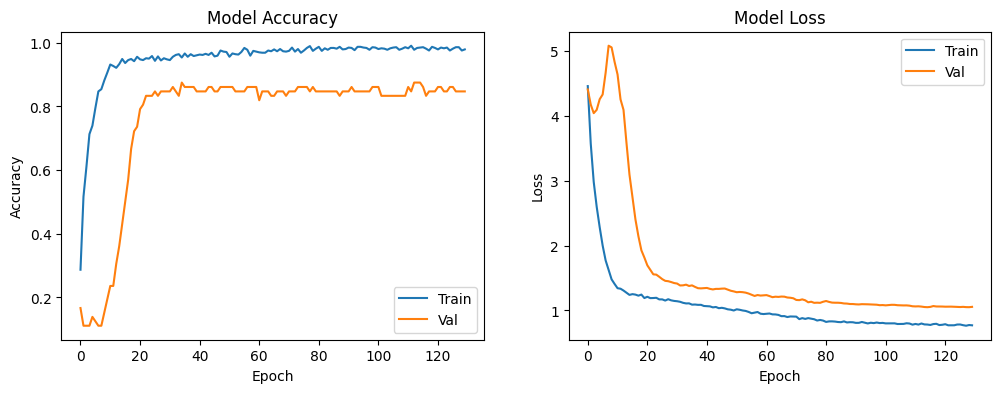

In [4]:
# --- MODEL ARCHITECTURE ---

# Build a Sequential model (layers stacked in order)
model = tf.keras.models.Sequential([
    
    # --- Block 1: Basic Patterns ---
    # Increase L2 to 0.01 to force the AI to keep weights small (prevents overfitting)
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same', 
                           input_shape=(MAX_FRAMES, N_MFCC - 1, 1),
                           kernel_regularizer=l2(0.01)), 
    tf.keras.layers.BatchNormalization(), # Stabilizes math across batches
    tf.keras.layers.MaxPooling2D(2,2),    # Reduces image size to focus on main features
    tf.keras.layers.Dropout(0.3),         # Randomly shuts off 30% of neurons to stop memorization

    # --- Block 2: Intermediate Textures ---
    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same',
                           kernel_regularizer=l2(0.01)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Dropout(0.4),         # Higher dropout as go deeper

    # --- Block 3: Complex Animal Signatures ---
    tf.keras.layers.Conv2D(128, (3,3), activation='relu', padding='same',
                           kernel_regularizer=l2(0.01)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Dropout(0.4),

    # --- Output Processing ---
    # Averages the features over time so it doesn't matter when the sound happens
    tf.keras.layers.GlobalAveragePooling2D(), 
    
    # Final dense "Brain" layer
    tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
    tf.keras.layers.Dropout(0.5),         # 50% dropout for maximum generalization
    
    # Output layer with 9 neurons (one for each animal)
    tf.keras.layers.Dense(len(le.classes_), activation='softmax')
])

# Compile using Adam optimizer
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# --- SMART CALLBACKS ---

# Create a tool that automatically lowers the "speed" of learning
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', # Watch the "Mock Exam" error score (Validation Loss)
    factor=0.2,         # If it stops improving, cut the learning speed by 80%
    patience=5,         # Wait for 5 loops (epochs) of no improvement before acting
    min_lr=0.00001      # Set a floor so the learning speed never hits zero
)

# Stops the training automatically when it's no longer learning
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=15,               # Stop if no improvement for 15 epochs
    restore_best_weights=True  # Roll back to the version that had the best Val score
)

# --- TRAINING ---
print("Training Model...")

# 'history' stores the logs of accuracy and loss
history = model.fit(
    X_train, y_train,                   # The Training Data and the correct answers (Labels)
    validation_data=(X_val, y_val),     # The "Mock Exam" data the AI hasn't seen before
    epochs=200,                         # Maximum number of times to study the whole dataset
    batch_size=32,                      # Number of audio files processed before updating the brain
    verbose=2,                          # One line per epoch (cleaner log)
    callbacks=[reduce_lr, early_stop]   # Control the training
)

# --- PLOTTING RESULTS ---
plt.figure(figsize=(12, 4))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.show()

### Evaluation & TFLite Export

Evaluate on the held-out Test Set using a Confusion Matrix to spot specific misclassifications (e.g., Dog vs Pig).

1/3 [=========>....................] - ETA: 1s

3/3 [==============================] - 1s 9ms/step


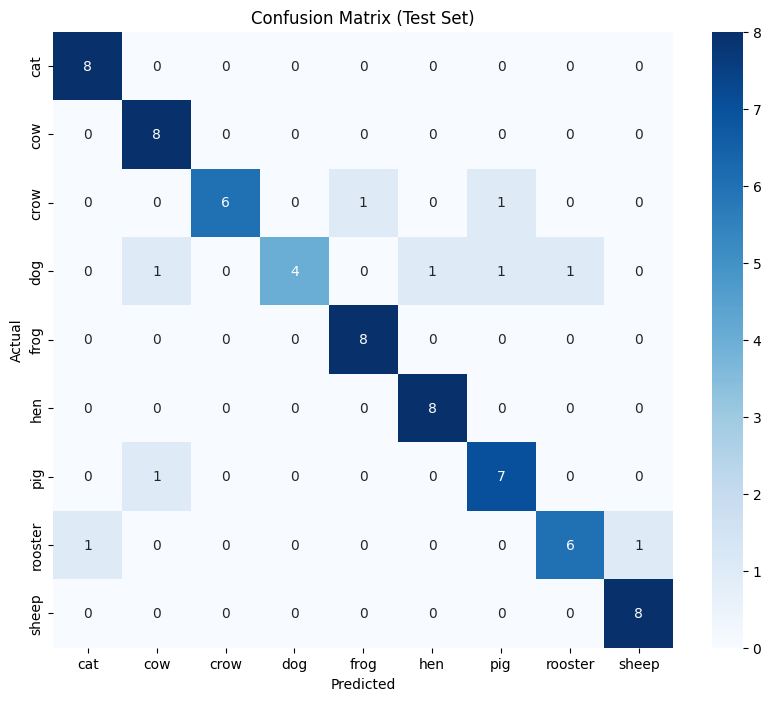

              precision    recall  f1-score   support

         cat       0.89      1.00      0.94         8
         cow       0.80      1.00      0.89         8
        crow       1.00      0.75      0.86         8
         dog       1.00      0.50      0.67         8
        frog       0.89      1.00      0.94         8
         hen       0.89      1.00      0.94         8
         pig       0.78      0.88      0.82         8
     rooster       0.86      0.75      0.80         8
       sheep       0.89      1.00      0.94         8

    accuracy                           0.88        72
   macro avg       0.89      0.88      0.87        72
weighted avg       0.89      0.88      0.87        72

Exporting model for Web...


Success! Model saved to eduaudio/web_app/model.tflite


In [5]:
# --- EVALUATION ---

# Make the AI predict answers for the Validation data (Data it hasn't trained on)
y_pred = model.predict(X_val)
# Convert probabilities (e.g. [0.1, 0.8, 0.1]) into a single class ID (e.g. 1)
y_pred_classes = np.argmax(y_pred, axis=1)
# Convert the actual true answers from One-Hot ([0, 1, 0]) into class ID (1)
y_true = np.argmax(y_val, axis=1)

# --- CONFUSION MATRIX ---
# Create a matrix comparing True Answers vs Predicted Answers
cm = confusion_matrix(y_true, y_pred_classes)
# Setup the figure size
plt.figure(figsize=(10, 8))
# Draw the Heatmap using Seaborn
# annot=True shows numbers, fmt='d' means integers, cmap='Blues' makes it blue
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
# Add labels
plt.title("Confusion Matrix (Test Set)")
plt.ylabel('Actual')
plt.xlabel('Predicted')
# Show the chart
plt.show()

# --- CLASSIFICATION REPORT ---
# Print detailed stats (Precision, Recall, F1-Score) for every animal
print(classification_report(y_true, y_pred_classes, target_names=le.classes_))

# --- EXPORT TO TFLITE ---
print("Exporting model for Web...")
# Create a converter tool from our Keras model
converter = tf.lite.TFLiteConverter.from_keras_model(model)
# Convert the Python model into a TFLite model (optimized for mobile/web)
tflite_model = converter.convert()

# Save the binary .tflite file into the web app folder
with open("../eduaudio/web_app/model.tflite", 'wb') as f:
    f.write(tflite_model)
    
# Print success message
print("Success! Model saved to eduaudio/web_app/model.tflite")